In [1]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import average_precision_score
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification
import numpy as np
from sklearn.metrics import precision_recall_curve,auc,roc_auc_score

In [ ]:
def stat_precision_recal(filename,soft):
    y_test,y_scores=[],[]
    with open(filename) as f:
        for eachline in f:
            
            if "peptide" not in eachline and "measurement_value" not in eachline:
                line=eachline.strip().split("\t")
                if soft=="LKMHCpan":
                    if len(line[0])>=8 and len(line[0])<=15: #限制肽段长度
                        y_test.append(int(line[-1]))
                        score=float(line[3].split(",")[1].replace("]",""))
                        y_scores.append(score)
                        #print(line[2])
            
                elif soft=="NetMHCpan_EL":
                    line=eachline.strip().split()
                    #update后
                    if len(line[4])>=8 and len(line[4])<=15: #限制肽段长度
                        y_test.append(int(line[0]))
                        score=-float(line[14])  
                        y_scores.append(score)
                        #print(line[1])                 
                elif soft=="NetMHCpan_BA":
                    #update后
                    max,min=49873.02,1.20
                    line=eachline.strip().split()
                    if len(line[4])>=8 and len(line[4])<=15: #限制肽段长度
                        y_test.append(int(line[0]))
                        #print(line[17])
                        score=-(float(line[17]))   
                        y_scores.append(score)
                elif soft=="MixMHCpred2.2" :
                    line=eachline.strip().split("\t")
                    if len(line[2])>=8 and len(line[2])<=15: #限制肽段长度
                        y_test.append(int(line[0]))
                        score=-(float(line[-1]))
                        #print(line[-1])
                        y_scores.append(score)
                        #print(line[1])        
                elif soft=="mhcflurry":
                    line=eachline.strip().split(",")
                    if len(line[0])>=8 and len(line[0])<=15: #限制肽段长度
                        if line[5]!="":
                            y_test.append(int(line[1]))
                            score=-(round(float(line[5]),3))
                            #score=(float(line[5]))/100
                            y_scores.append(score)
                            #print(line[3])                      

    precision,recall,_= precision_recall_curve(y_test, y_scores)
    auc_pr = auc(recall, precision)
    roc_auc = roc_auc_score(y_test, y_scores)
    average_precision = round(average_precision_score(y_test, y_scores),3)    
    average_precision=round(average_precision,2)
    print(f"{soft} AUC_PR: {auc_pr:.4f} ROC_AUC: {roc_auc:.4f} AP: {average_precision}")
    return  round(auc_pr,2), round(roc_auc,2),precision, recall,average_precision

In [3]:
LKfile="iedb_derived_Data_final.predict.format.xls"
netfile="iedb_derived_Data_final-netmhcpna4.1-result.xls"
mhcflurryfile="iedb_derived_Data_final-mhcflurry-result.csv"
mixfile="iedb_derived_Data_final-MixMHCpred2.2-result.xls"

In [4]:
auc_prlk,roc_auclk,precisionlk,recalllk,average_precisionlk=stat_precision_recal(LKfile,"LKMHCpan")
auc_prEL,roc_aucEL,precisionEL,recallnEL,average_precisionEL=stat_precision_recal(netfile,"NetMHCpan_EL")
auc_prBA,roc_aucBA,precisionBA,recallBA,average_precisionBA=stat_precision_recal(netfile,"NetMHCpan_BA")
auc_prmhcflurry,roc_aucmhcflurry,precisionmhcflurry,recallmhcflurry,average_precisionmhcflurry=stat_precision_recal(mhcflurryfile,"mhcflurry")
auc_prmix,roc_aucmix,precisionmix,recallmix,average_precisionmix=stat_precision_recal(mixfile,"MixMHCpred2.2")

LKMHCpan AUC_PR: 0.8399 ROC_AUC: 0.9754 AP: 0.84
NetMHCpan_EL AUC_PR: 0.7554 ROC_AUC: 0.9216 AP: 0.76
NetMHCpan_BA AUC_PR: 0.6314 ROC_AUC: 0.8981 AP: 0.63
mhcflurry AUC_PR: 0.7652 ROC_AUC: 0.9527 AP: 0.76
MixMHCpred2.2 AUC_PR: 0.7409 ROC_AUC: 0.9253 AP: 0.74


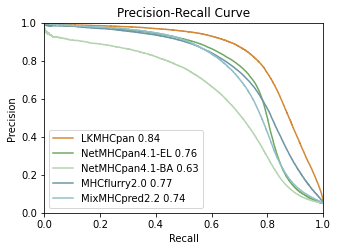

In [5]:
# 绘制PR曲线
plt.figure(figsize=(5, 3.5)) 
plt.step(recalllk, precisionlk, where='post', label='LKMHCpan '+str(auc_prlk),color="#D28A39") # AP: {average_precisionlk:.2f}') #Average Precision
plt.step(recallnEL, precisionEL, where='post', label='NetMHCpan4.1-EL '+str(auc_prEL),color="#6FA961")# AP: {average_precisionnet:.2f}')
plt.step(recallBA, precisionBA, where='post', label='NetMHCpan4.1-BA '+str(auc_prBA),color="#B4D5AF")# AP: {average_precisionnet:.2f}')
plt.step(recallmhcflurry, precisionmhcflurry, where='post', label='MHCflurry2.0 '+str(auc_prmhcflurry),color="#6E96A7")# AP: {average_precisionmhcflurry:.2f}')
plt.step(recallmix, precisionmix, where='post', label='MixMHCpred2.2 '+str(auc_prmix),color="#91C0C7")# AP: {average_precisionmix:.2f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.ylim([0.0, 1.0])
plt.xlim([0.0, 1.0])
plt.title('Precision-Recall Curve')
plt.legend(loc='lower left')
plt.savefig("PRAUC_of_each_software_IEDBderived_LKMHCpan.svg")
plt.show()